# Model: K-means and KNN

Input: `data/stocks_clean.csv`, containing only Ticker, Market_capital, and PEG ratio.
Exclude Ticker from model features. Save figures and result tables to `outputs/`.

This notebook is a workflow template. The TODO sections have not been implemented.


In [5]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

## 1. Load Data and Process Features

Validate columns and numerical values. Choose market capitalization transformations and a standardization method. Apply the same fitted processing to new stocks.


In [7]:
# Load data 
ROOT = Path.cwd()
if not (ROOT / "data/equity_data.csv").exists():
    ROOT = ROOT.parent

df = pd.read_csv(ROOT / "data/equity_data.csv")
df.head()

,Ticker,Market_capital,PEG ratio
0,RLJ,2.023031e+09,4.680005
1,FVR,5.152375e+08,NaN
2,BKD,2.214870e+09,NaN
3,RRR,5.268382e+09,6.189660
4,IVT,2.478155e+09,2.987124


In [9]:
features = ["Market_capital", "PEG ratio"]
numeric = df[features].apply(pd.to_numeric, errors="coerce")
valid = np.isfinite(numeric).all(axis=1) & numeric.gt(0).all(axis=1)

stocks = df.loc[valid, ["Ticker"]].copy()
stocks[features] = numeric.loc[valid]

print(f"Stocks used for clustering: {len(stocks):,}")

Stocks used for clustering: 1,161


In [ ]:
# data log transformation
X_log = np.log10(stocks[features])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)



## 2. K-means Clustering with Nine Clusters

Set n_clusters=9 and a fixed random seed. Verify that there are enough valid stocks and distinct feature points to form nine clusters.
Inspect cluster sizes, cluster centers, and a scatter plot.


In [11]:
kmeans = KMeans(
    n_clusters=9,
    random_state=42,
    n_init=20,
)

stocks["Cluster"] = kmeans.fit_predict(X_scaled)


In [12]:
score = silhouette_score(X_scaled, stocks["Cluster"])
print(f"Silhouette score: {score:.3f}")

# 5. Summarize clusters in original units
summary = (
    stocks.groupby("Cluster")
    .agg(
        Stock_count=("Ticker", "size"),
        Median_market_cap=("Market_capital", "median"),
        Median_PEG=("PEG ratio", "median"),
    )
)

display(summary.round(2))

Silhouette score: 0.342


,Stock_count,Median_market_cap,Median_PEG
Cluster,,,
0,71,7.351379e+08,35.73
1,136,2.635911e+09,0.17
2,176,8.854925e+08,0.85
3,43,5.700667e+08,0.05
4,105,3.436902e+09,11.21
5,124,3.414121e+08,3.69
6,116,2.762996e+08,0.49
7,221,4.316114e+09,1.50
8,169,1.464354e+09,3.24


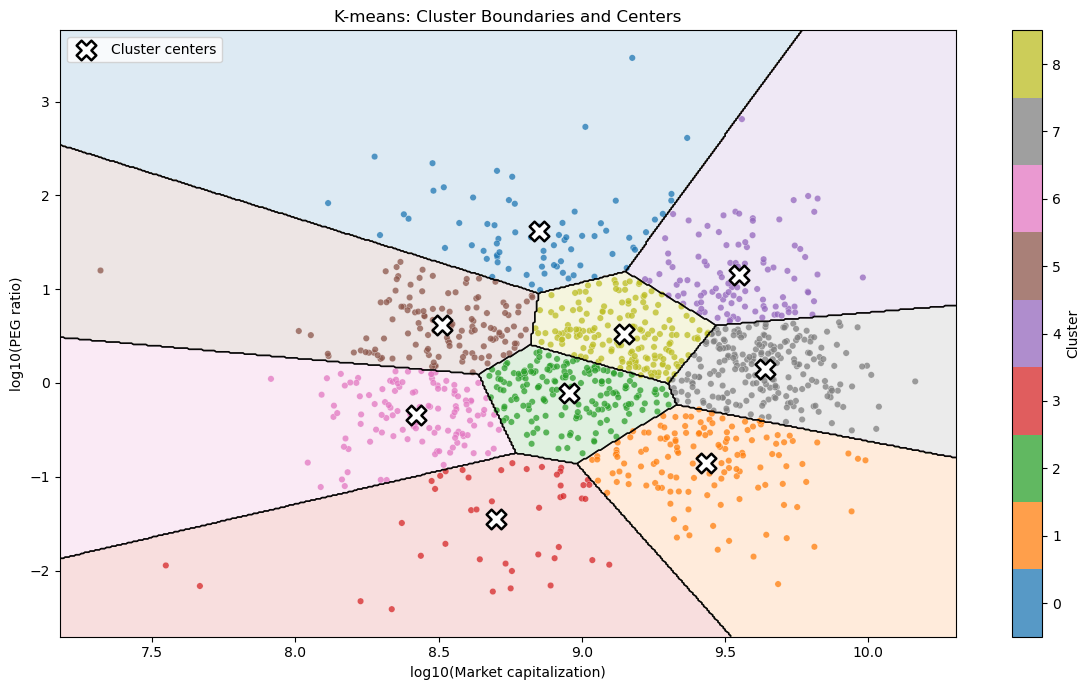

,Ticker,Market_capital,PEG ratio,Cluster
0,RLJ,2.023031e+09,4.680005,8
3,RRR,5.268382e+09,6.189660,4
4,IVT,2.478155e+09,2.987124,8
5,HOG,3.443334e+09,1.680040,7
6,FWRG,8.320736e+08,37.802195,0
8,IBP,5.633310e+09,1.506817,7
9,RDNT,6.168862e+09,98.457005,4
10,KRG,5.084775e+09,0.233085,1
11,SBRA,5.492022e+09,88.989084,4
12,NTST,2.337401e+09,12.464000,4


In [7]:
from matplotlib.colors import ListedColormap

# Build a grid in log10 space and predict using the fitted scaler.
x = X_log["Market_capital"]
y = X_log["PEG ratio"]
x_pad = (x.max() - x.min()) * 0.05
y_pad = (y.max() - y.min()) * 0.05
xx, yy = np.meshgrid(
    np.linspace(x.min() - x_pad, x.max() + x_pad, 500),
    np.linspace(y.min() - y_pad, y.max() + y_pad, 500),
)
grid = pd.DataFrame(
    np.column_stack([xx.ravel(), yy.ravel()]),
    columns=X_log.columns,
)
regions = kmeans.predict(scaler.transform(grid)).reshape(xx.shape)
centers_log = scaler.inverse_transform(kmeans.cluster_centers_)
n_clusters = kmeans.n_clusters
cmap = ListedColormap(plt.get_cmap("tab10").colors[:n_clusters])

fig, ax = plt.subplots(figsize=(12, 7))

# Shade cluster regions and outline each region independently.
ax.contourf(
    xx, yy, regions,
    levels=np.arange(n_clusters + 1) - 0.5,
    cmap=cmap, alpha=0.15,
)
for cluster in range(n_clusters):
    mask = (regions == cluster).astype(float)
    if mask.min() != mask.max():
        ax.contour(
            xx, yy, mask, levels=[0.5],
            colors="black", linewidths=1.1, alpha=0.8,
        )

points = ax.scatter(
    x, y, c=stocks["Cluster"], cmap=cmap,
    vmin=-0.5, vmax=n_clusters - 0.5,
    s=22, alpha=0.75, edgecolors="white", linewidths=0.25,
)

ax.scatter(
    centers_log[:, 0], centers_log[:, 1],
    facecolors="white", marker="X", s=200,
    edgecolors="black", linewidths=1.8,
    label="Cluster centers", zorder=5,
)

ax.set(
    xlabel="log10(Market capitalization)",
    ylabel="log10(PEG ratio)",
    title="K-means: Cluster Boundaries and Centers",
    xlim=(xx.min(), xx.max()), ylim=(yy.min(), yy.max()),
)
fig.colorbar(points, ax=ax, ticks=range(n_clusters), label="Cluster")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

display(stocks.head(10))


## 3. Unique 3 x 3 Cluster Labels and Representative Stocks

Use each combination of Small/Mid/Large and Value/Core/Growth exactly once, without changing the fitted K-means clusters.

1. Sort the nine clusters by median market capitalization. Assign the lowest three to Small cap, the middle three to Mid cap, and the highest three to Large cap.
2. Within each size group, sort its three clusters by median PEG. Assign Value, Core, and Growth in ascending PEG order.
3. Retain the stock closest to each cluster center in standardized log10 feature space as its representative.

This is a constrained, sample-relative naming convention, not a new clustering algorithm. Each size group contains three clusters, not an equal number of stocks. Size bands do not represent market-wide capitalization thresholds. Style labels represent relative PEG ordering within each size group; a high PEG alone does not demonstrate high earnings growth. They are not official Morningstar classifications, which use separate multi-factor value and growth scores (see `Stylebox_Factsheet.pdf`).

Representatives are geometrically central observations, not investment recommendations.


In [7]:
# Assign each of the nine size/style combinations exactly once.
cluster_labels = summary.sort_values(["Median_market_cap", "Median_PEG"]).copy()
cluster_labels["Size label"] = np.repeat(["Small cap", "Mid cap", "Large cap"], 3)

# Sort PEG within each size group, then assign Value, Core, and Growth.
cluster_labels = cluster_labels.sort_values(["Size label", "Median_PEG", "Median_market_cap"])
cluster_labels["Style proxy"] = np.tile(["Value", "Core", "Growth"], 3)
cluster_labels["Cluster label"] = cluster_labels["Size label"] + " / " + cluster_labels["Style proxy"]
cluster_labels = cluster_labels.sort_index()
display(cluster_labels.round(4))

# Display the complete 3 x 3 mapping.
style_box = cluster_labels.reset_index().pivot(
    index="Size label", columns="Style proxy", values="Cluster"
).reindex(index=["Small cap", "Mid cap", "Large cap"], columns=["Value", "Core", "Growth"])
display(style_box.rename_axis(index="Size", columns="Style (PEG proxy)"))


,Stock_count,Median_market_cap,Median_PEG,Size label,Style proxy,Cluster label
Cluster,,,,,,
0,71,7.351379e+08,35.7306,Mid cap,Growth,Mid cap / Growth
1,136,2.635911e+09,0.1671,Large cap,Value,Large cap / Value
2,176,8.854925e+08,0.8489,Mid cap,Value,Mid cap / Value
3,43,5.700667e+08,0.0547,Small cap,Value,Small cap / Value
4,105,3.436902e+09,11.2075,Large cap,Growth,Large cap / Growth
5,124,3.414121e+08,3.6878,Small cap,Growth,Small cap / Growth
6,116,2.762996e+08,0.4943,Small cap,Core,Small cap / Core
7,221,4.316114e+09,1.4963,Large cap,Core,Large cap / Core
8,169,1.464354e+09,3.2423,Mid cap,Core,Mid cap / Core


Style (PEG proxy),Value,Core,Growth
Size,,,
Small cap,3,6,5
Mid cap,2,8,0
Large cap,1,7,4


In [8]:
# Work on a copy so existing stocks, features, and cluster assignments stay unchanged.
labeled_stocks = stocks.copy()
labeled_stocks["Cluster label"] = labeled_stocks["Cluster"].map(cluster_labels["Cluster label"])
labeled_stocks["Distance to center"] = np.linalg.norm(
    X_scaled - kmeans.cluster_centers_[stocks["Cluster"].to_numpy()], axis=1
)
representative_stocks = (
    labeled_stocks.sort_values(["Cluster", "Distance to center", "Ticker"])
    .groupby("Cluster", sort=True).head(1)
    [["Cluster", "Cluster label", "Ticker", "Market_capital", "PEG ratio", "Distance to center"]]
    .reset_index(drop=True)
)
display(representative_stocks.round(4))


,Cluster,Cluster label,Ticker,Market_capital,PEG ratio,Distance to center
0,0,Mid cap / Growth,BFS,7.097577e+08,46.4124,0.0619
1,1,Large cap / Value,ARDT,2.572089e+09,0.1591,0.0829
2,2,Mid cap / Value,WGO,8.984260e+08,0.7781,0.0083
3,3,Small cap / Value,JAKK,4.289747e+08,0.0447,0.1976
4,4,Large cap / Growth,REZI,3.413122e+09,12.9532,0.0556
5,5,Small cap / Growth,ARL,3.500148e+08,4.0470,0.0709
6,6,Small cap / Core,ASLE,2.518821e+08,0.4600,0.0401
7,7,Large cap / Core,HCC,4.430095e+09,1.4665,0.0299
8,8,Mid cap / Core,IBTA,1.408040e+09,2.9792,0.0608


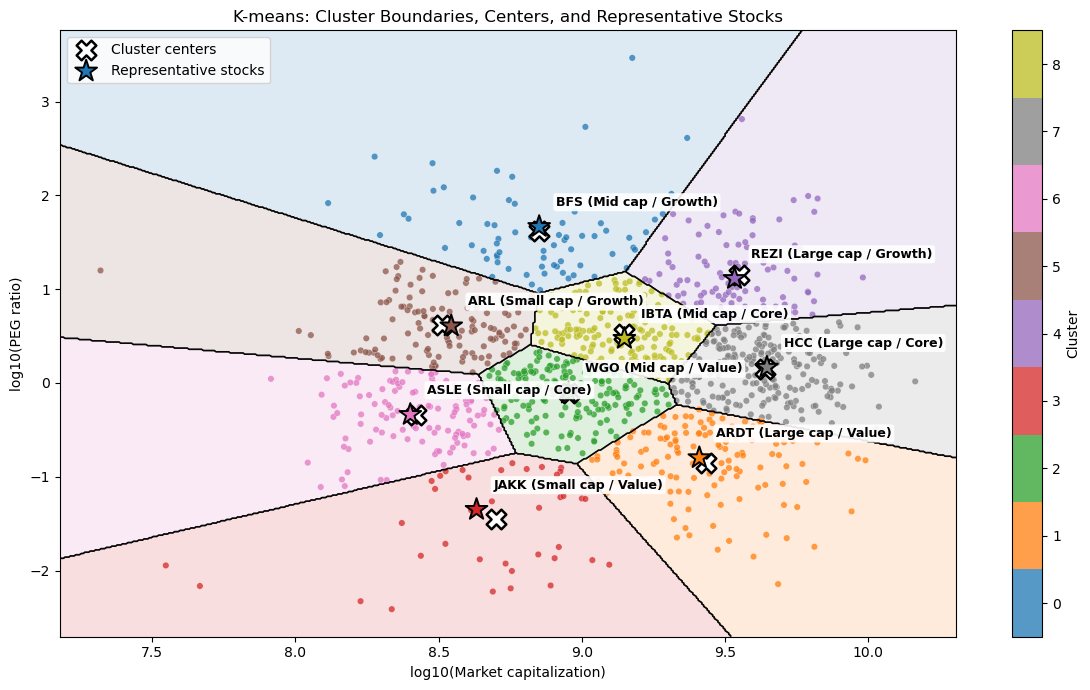

In [9]:
from matplotlib.colors import ListedColormap

# Build a grid in log10 space and predict using the fitted scaler.
x = X_log["Market_capital"]
y = X_log["PEG ratio"]
x_pad = (x.max() - x.min()) * 0.05
y_pad = (y.max() - y.min()) * 0.05
xx, yy = np.meshgrid(
    np.linspace(x.min() - x_pad, x.max() + x_pad, 500),
    np.linspace(y.min() - y_pad, y.max() + y_pad, 500),
)
grid = pd.DataFrame(
    np.column_stack([xx.ravel(), yy.ravel()]),
    columns=X_log.columns,
)
regions = kmeans.predict(scaler.transform(grid)).reshape(xx.shape)
centers_log = scaler.inverse_transform(kmeans.cluster_centers_)
n_clusters = kmeans.n_clusters
cmap = ListedColormap(plt.get_cmap("tab10").colors[:n_clusters])

fig, ax = plt.subplots(figsize=(12, 7))

# Shade cluster regions and outline each region independently.
ax.contourf(
    xx, yy, regions,
    levels=np.arange(n_clusters + 1) - 0.5,
    cmap=cmap, alpha=0.15,
)
for cluster in range(n_clusters):
    mask = (regions == cluster).astype(float)
    if mask.min() != mask.max():
        ax.contour(
            xx, yy, mask, levels=[0.5],
            colors="black", linewidths=1.1, alpha=0.8,
        )

points = ax.scatter(
    x, y, c=stocks["Cluster"], cmap=cmap,
    vmin=-0.5, vmax=n_clusters - 0.5,
    s=22, alpha=0.75, edgecolors="white", linewidths=0.25,
)

ax.scatter(
    centers_log[:, 0], centers_log[:, 1],
    facecolors="white", marker="X", s=200,
    edgecolors="black", linewidths=1.8,
    label="Cluster centers", zorder=5,
)

# Representatives are separate stock observations, not fitted centers.
ax.scatter(
    np.log10(representative_stocks["Market_capital"]),
    np.log10(representative_stocks["PEG ratio"]),
    c=representative_stocks["Cluster"], cmap=cmap,
    vmin=-0.5, vmax=n_clusters - 0.5,
    marker="*", s=270, edgecolors="black", linewidths=1.4,
    label="Representative stocks", zorder=7,
)
for row in representative_stocks.itertuples(index=False, name=None):
    cluster, label, ticker, market_cap, peg, distance = row
    ax.annotate(
        f"{ticker} ({label})",
        (np.log10(market_cap), np.log10(peg)),
        xytext=(12, 15), textcoords="offset points",
        fontsize=9, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="none", alpha=0.9),
        zorder=8,
    )

ax.set(
    xlabel="log10(Market capitalization)", ylabel="log10(PEG ratio)",
    title="K-means: Cluster Boundaries, Centers, and Representative Stocks",
    xlim=(xx.min(), xx.max()), ylim=(yy.min(), yy.max()),
)
fig.colorbar(points, ax=ax, ticks=range(n_clusters), label="Cluster")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


## 4. KNN Labels and Evaluation Design

Explicitly choose K-means or Morningstar as the label source, then select the number of neighbors and evaluation method.
When KNN uses K-means labels, evaluation measures how well it reproduces the clustering rule; it does not measure Morningstar classification accuracy.
For holdout evaluation, split the data first, then fit transformations and relevant models on the training set to avoid data leakage.


In [ ]:
# TODO: Build KNN and document the label source, number of neighbors, and evaluation results.


## 5. New-Stock Classification and Output

Provide the same three input columns for a new stock. Verify consistent definitions and units, and apply the feature transformations fitted during training.
Report the predicted class, neighboring stocks, and an explanation. Document limitations if the new stock falls outside the training data range.
Result tables may include cluster and prediction columns; raw and cleaned inputs must retain only the three original columns.


In [ ]:
# TODO: Provide a new stock and save prediction results to OUTPUT_DIR.
